<a href="https://colab.research.google.com/github/kc281/IA_CLASIFICADOR_DE_RESIDUOS/blob/main/ENTRENAMIENTO_DE_MODELOipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TensorFlow version: 2.21.0
Dividiendo dataset en train/val/test...
 Dataset dividido correctamente.
Calculando pesos de clase...
Pesos calculados: {0: np.float64(1.7100204498977505), 1: np.float64(0.8463562753036438), 2: np.float64(1.2844854070660523), 3: np.float64(0.894331550802139), 4: np.float64(0.7479427549194991)}
Cargando datos con image_dataset_from_directory...
Found 4181 files belonging to 5 classes.
Found 896 files belonging to 5 classes.
Found 896 files belonging to 5 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

 Iniciando Fase 1: Feature Extraction...
Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 71s 449ms/step - accuracy: 0.2155 - loss: 1.7890 - val_accuracy: 0.4654 - val_loss: 1.3102
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 51s 387ms/step - accuracy: 0.2519 - loss: 1.6716 - val_accuracy: 0.5893 - val_loss: 1.1009
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 51s 390ms/step - accuracy: 0.2578 - loss: 1.6284 - val_accuracy: 0.5893 - val_loss: 1.0208
Epoch 4/10
131/131 ━━━

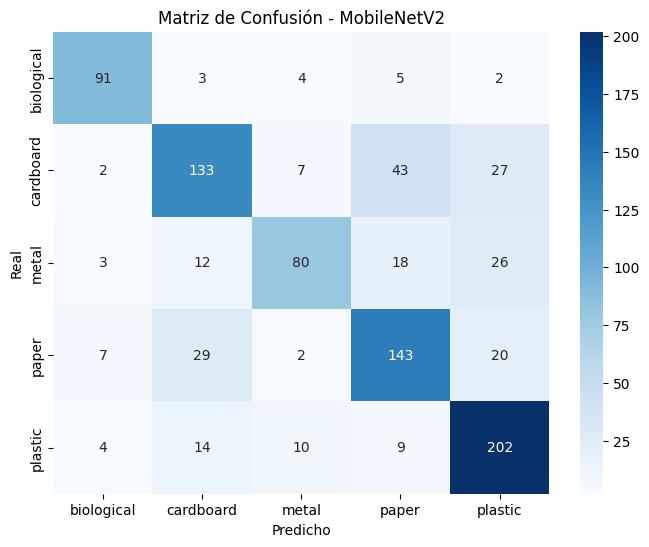


✅ Modelo guardado como 'mobilenetv2_waste.h5'


In [8]:
import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models, optimizers, callbacks

# ==========================================
# 1. CONFIGURACIÓN DE RUTAS
# ==========================================
RUTA_DATASET_ORIGINAL = "/content/drive/MyDrive/DATASET_IA_standardized_256"
RUTA_SPLIT = "/content/dataset_split"

CLASES = ["biological", "cardboard", "metal", "paper", "plastic"]
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print("TensorFlow version:", tf.__version__)

# ==========================================
# 2. PARTICIPACIÓN ESTRATIFICADA (70/15/15)
# ==========================================
if os.path.exists(RUTA_SPLIT):
    print("La carpeta de split ya existe. Saltando división...")
else:
    print("Dividiendo dataset en train/val/test...")
    files, labels = [], []
    extensiones = {".jpg", ".jpeg", ".png", ".webp"}

    # Leer archivos
    for cls in CLASES:
        carpeta = Path(RUTA_DATASET_ORIGINAL) / cls
        if carpeta.exists():
            for f in carpeta.iterdir():
                if f.suffix.lower() in extensiones:
                    files.append(f)
                    labels.append(cls)

    # Split 70/15/15
    X_train, X_temp, y_train, y_temp = train_test_split(
        files, labels, test_size=0.30, stratify=labels, random_state=42)
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

    # Copiar a carpetas
    for split_name, Xs, ys in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
        for src, cls in zip(Xs, ys):
            out_dir = Path(RUTA_SPLIT) / split_name / cls
            out_dir.mkdir(parents=True, exist_ok=True)
            shutil.copy2(src, out_dir / src.name)
    print(" Dataset dividido correctamente.")

# ==========================================
# 3. CALCULAR PESOS DE CLASE (Para el desbalance)
# ==========================================
print("Calculando pesos de clase...")
y_train_array = np.array(y_train)
weights = compute_class_weight(class_weight="balanced", classes=np.unique(y_train_array), y=y_train_array)
class_weights = dict(enumerate(weights))
print("Pesos calculados:", class_weights)


# ==========================================
# 4. CARGA DE DATOS CON IMAGE_DATASET_FROM_DIRECTORY
# ==========================================
print("Cargando datos con image_dataset_from_directory...")

# 1. Cargar el conjunto de entrenamiento
train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{RUTA_SPLIT}/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # Para que coincida con la función de pérdida
    shuffle=True,
    seed=42
)

# 2. Cargar el conjunto de validación
val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{RUTA_SPLIT}/val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False
)

# 3. Cargar el conjunto de prueba
test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{RUTA_SPLIT}/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False
)

# --- Aumentación de datos---
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),      # Rotación de ±36 grados (0.1 * 360)
    layers.RandomZoom(0.15),
    layers.RandomBrightness(0.2),
    layers.RandomContrast(0.1),
])

# --- Función para aplicar rescale y aumentación solo al conjunto de entrenamiento ---
def preprocess_train(image, label):
    image = tf.cast(image, tf.float32) / 255.0  # Rescale
    image = data_augmentation(image, training=True)
    return image, label

def preprocess_val_test(image, label):
    image = tf.cast(image, tf.float32) / 255.0  # Rescale
    return image, label

# Aplicamos las transformaciones
train_ds = train_ds.map(preprocess_train)
val_ds = val_ds.map(preprocess_val_test)
test_ds = test_ds.map(preprocess_val_test)

# Optimización para el rendimiento
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)


# ==========================================
# 5. CREAR EL MODELO (MobileNetV2 + Transfer Learning)
# ==========================================
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False # Fase 1: Congelado

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(5, activation='softmax')
])

model.compile(optimizer=optimizers.Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])

# Callbacks
early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# ==========================================
# 6. ENTRENAMIENTO - FASE 1
# ==========================================
print("\n Iniciando Fase 1: Feature Extraction...")
history1 = model.fit(
    train_ds,                  # <-- CAMBIADO: Usar train_ds
    epochs=10,
    validation_data=val_ds,    # <-- CAMBIADO: Usar val_ds
    class_weight=class_weights,
    callbacks=[early_stop]
)

# ==========================================
# 7. ENTRENAMIENTO - FASE 2
# ==========================================
print("\n Iniciando Fase 2: Fine-Tuning...")
base_model.trainable = True
# Descongelar solo las últimas 30 capas
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(optimizer=optimizers.Adam(1e-5), loss='categorical_crossentropy', metrics=['accuracy'])

history2 = model.fit(
    train_ds,                  # <-- CAMBIADO: Usar train_ds
    epochs=10,
    validation_data=val_ds,    # <-- CAMBIADO: Usar val_ds
    class_weight=class_weights,
    callbacks=[early_stop]
)

# ==========================================
# 8. EVALUACIÓN Y MÉTRICAS
# ==========================================
print("\n📊 Evaluando en el conjunto de prueba...")

# Extraer las etiquetas reales de test_ds
y_true = np.concatenate([np.argmax(y, axis=1) for x, y in test_ds], axis=0)

# Predecir
preds = model.predict(test_ds)
y_pred = np.argmax(preds, axis=1)

f1_macro = f1_score(y_true, y_pred, average='macro')
print(f"\n⭐ F1-Macro: {f1_macro:.4f}")

print("\nReporte de Clasificación:")
print(classification_report(y_true, y_pred, target_names=CLASES))

# Matriz de confusión
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASES, yticklabels=CLASES)
plt.title('Matriz de Confusión - MobileNetV2')
plt.ylabel('Real')
plt.xlabel('Predicho')
plt.savefig('matriz_confusion.png')
plt.show()

# ==========================================
# 9. GUARDAR EL MODELO
# ==========================================
model.save("mobilenetv2_waste.keras")
print("\n✅ Modelo guardado como 'mobilenetv2_waste.h5'")

In [7]:
!rm -rf /content/dataset_split